# Tutorial 10 (T10): Building Programs to Implement Hierarchical Clustering

## 📌 Objective
Implement **Agglomerative Hierarchical Clustering** on the agricultural crop dataset (`Crop_recommendation.csv`). Identify natural agro-climatic clusters of crops without using target labels, visualize the cluster hierarchy via a **Dendrogram**, and examine the characteristics of each agro-ecological group.

## 🔬 Key Concepts & Mathematical Formulas
- **Hierarchical Clustering (Agglomerative)**: Bottom-up approach where each sample starts as its own cluster and pairs are recursively merged.
- **Euclidean Distance Metric**: $d(u, v) = \sqrt{\sum_{i=1}^p (u_i - v_i)^2}$
- **Ward's Minimum Variance Linkage**: Merges clusters that minimize the increase in total within-cluster variance:
  $$\Delta ESS = \frac{n_A n_B}{n_A + n_B} ||\mu_A - \mu_B||^2$$
- **Dendrogram**: Tree diagram depicting hierarchical arrangement of nested clusters and merge distances.

### Step 1: Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", palette="muted")
print('Libraries successfully imported!')

Libraries successfully imported!


### Step 2: Load and Inspect Crop Recommendation Dataset
We load `data/Crop_recommendation.csv` containing 7 numerical features: N, P, K, temperature, humidity, pH, and rainfall.

In [2]:
data_path = os.path.join('data', 'Crop_recommendation.csv')
df = pd.read_csv(data_path)
print(f'Dataset Shape: {df.shape}')
print(f'Features: {list(df.columns[:7])}')
print(f'Unique Crop Types: {df["label"].nunique()}')
display(df.head(6))

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice
5,69,37,42,23.058049,83.370118,7.073454,251.055000,rice


Dataset Shape: (2200, 8)
Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Unique Crop Types: 22


### Step 3: Feature Standardization
Clustering algorithms rely on Euclidean distances. Features with large scales (e.g., Rainfall up to 300 mm, Potassium up to 205 kg/ha) would dominate features with small scales (e.g., pH 3.5 - 9.9) without standardization.
$$z = \frac{x - \mu}{\sigma}$$

In [3]:
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df[features].values
y = df['label'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f'Scaled Matrix Shape: {X_scaled.shape}')
print(f'Feature Means: {np.round(X_scaled.mean(axis=0), 2)}')
print(f'Feature Stds:  {np.round(X_scaled.std(axis=0), 2)}')

Scaled Matrix Shape: (2200, 7)
Feature Means: [-0.  0. -0.  0. -0. -0.  0.]
Feature Stds:  [1. 1. 1. 1. 1. 1. 1.]


### Step 4: Construct Linkage Matrix & Plot Truncated Dendrogram
We compute the Ward linkage matrix and plot a dendrogram showing the top cluster merges to identify the optimal cutoff threshold.

Computing Ward linkage matrix (minimizing within-cluster variance)...


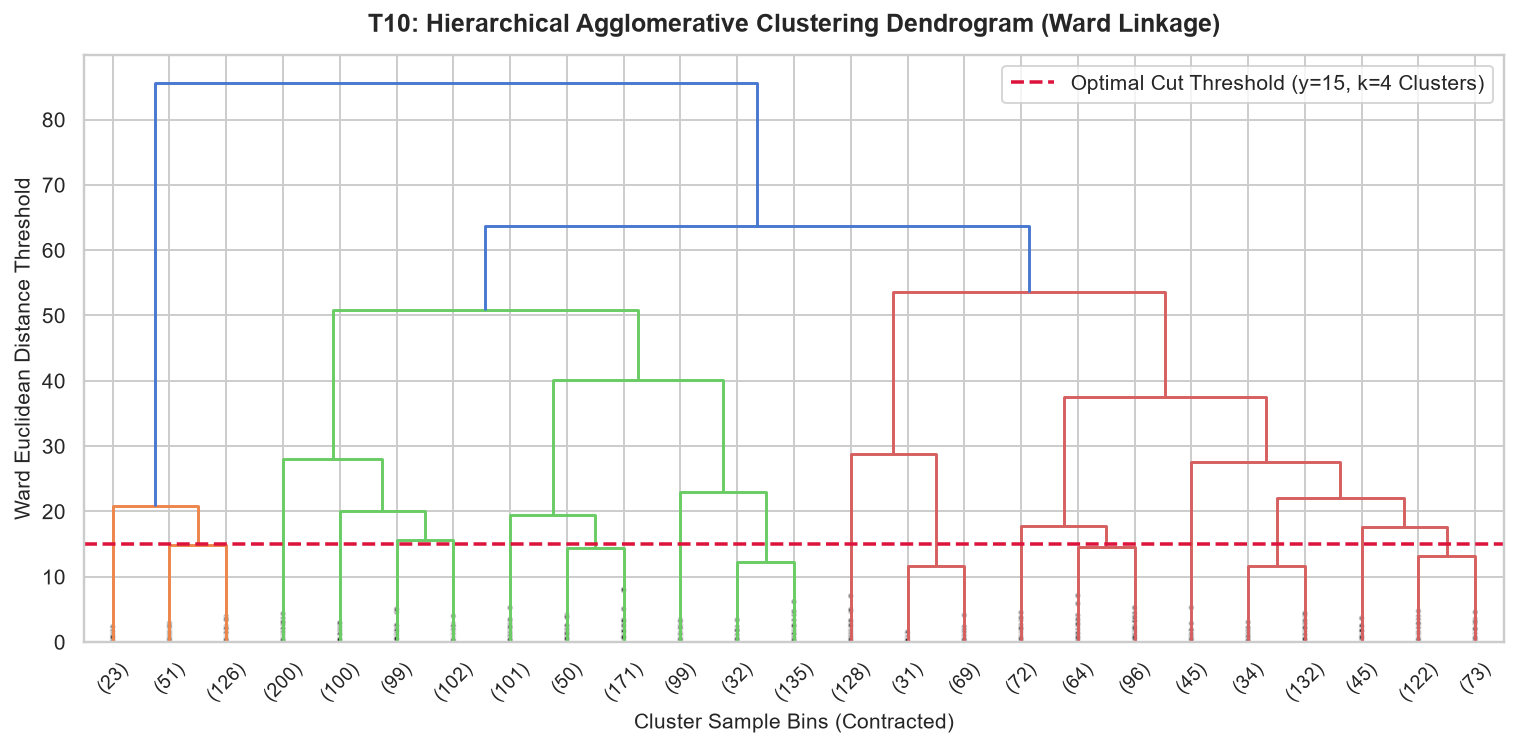

In [4]:
print('Computing Ward linkage matrix (minimizing within-cluster variance)...')
linkage_matrix = linkage(X_scaled, method='ward')

plt.figure(figsize=(11, 5.5), dpi=140)
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=25,
    leaf_rotation=45,
    leaf_font_size=10,
    show_contracted=True
)
plt.title('T10: Hierarchical Agglomerative Clustering Dendrogram (Ward Linkage)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Cluster Sample Bins (Contracted)', fontsize=11)
plt.ylabel('Ward Euclidean Distance Threshold', fontsize=11)
plt.axhline(y=15, color='crimson', linestyle='--', linewidth=1.8, label='Optimal Cut Threshold (y=15, k=4 Clusters)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Step 5: Fit Agglomerative Clustering Model ($k=4$)
Based on the prominent horizontal gap in the dendrogram, we fit `AgglomerativeClustering` with $k=4$ clusters.

In [5]:
k_clusters = 4
agg_model = AgglomerativeClustering(n_clusters=k_clusters, linkage='ward')
agg_labels = agg_model.fit_predict(X_scaled)

sil_score = silhouette_score(X_scaled, agg_labels)
print(f'Agglomerative Model Fitted with k={k_clusters}')
print(f'Overall Silhouette Score: {sil_score:.4f}')
cluster_counts = pd.Series(agg_labels).value_counts().sort_index()
for c_id, count in cluster_counts.items():
    print(f'  - Cluster {c_id + 1}: {count} samples ({count/len(df):.1%})')

Agglomerative Model Fitted with k=4
Overall Silhouette Score: 0.2592
  - Cluster 1: 1089 samples (49.5%)
  - Cluster 2: 228 samples (10.4%)
  - Cluster 3: 683 samples (31.0%)
  - Cluster 4: 200 samples (9.1%)


### Step 6: 2D Projection and Cluster Visualization via PCA
To visually inspect cluster separation in 2D space, we project the 7 standardized features onto the top 2 Principal Components (PC1 & PC2).

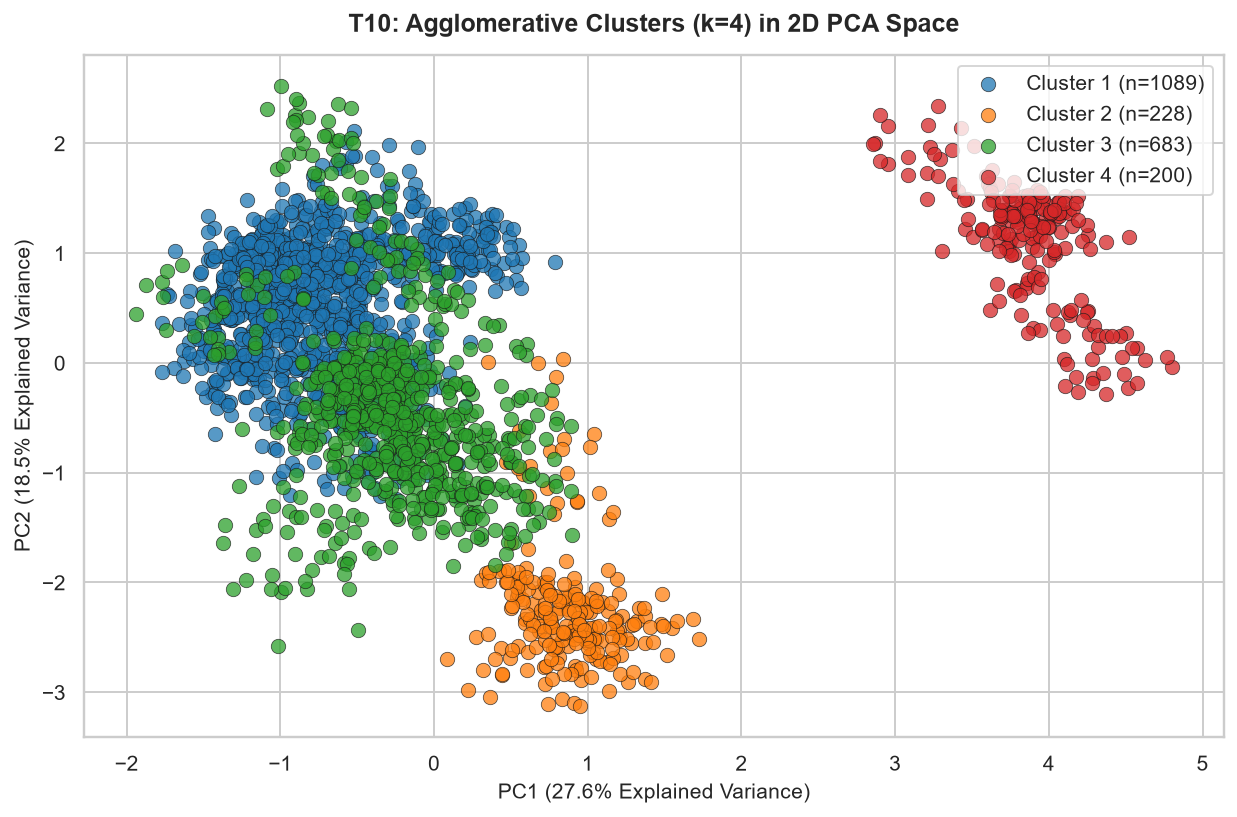

In [6]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6), dpi=140)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
for c in range(k_clusters):
    idx = (agg_labels == c)
    plt.scatter(
        X_pca[idx, 0], X_pca[idx, 1],
        label=f'Cluster {c+1} (n={idx.sum()})',
        color=colors[c], alpha=0.75, s=55, edgecolors='k', linewidth=0.4
    )

plt.title(f'T10: Agglomerative Clusters (k={k_clusters}) in 2D PCA Space', fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} Explained Variance)', fontsize=11)
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} Explained Variance)', fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

### Step 7: Agronomic Profiling & Cluster Mean Analysis
We inspect the centroid averages of soil nutrients and weather conditions in each cluster to interpret what each cluster represents in agricultural terms.

,N,P,K,temperature,humidity,ph,rainfall
Cluster,,,,,,,
Cluster 1,75.21,36.24,35.64,24.81,81.78,6.48,121.15
Cluster 2,28.86,67.69,46.35,19.77,22.36,6.37,99.84
Cluster 3,26.83,52.45,24.22,29.55,66.89,6.63,80.08
Cluster 4,21.99,133.38,200.00,23.24,87.10,5.98,91.13


=== Agro-Climatic Cluster Mean Profiles ===


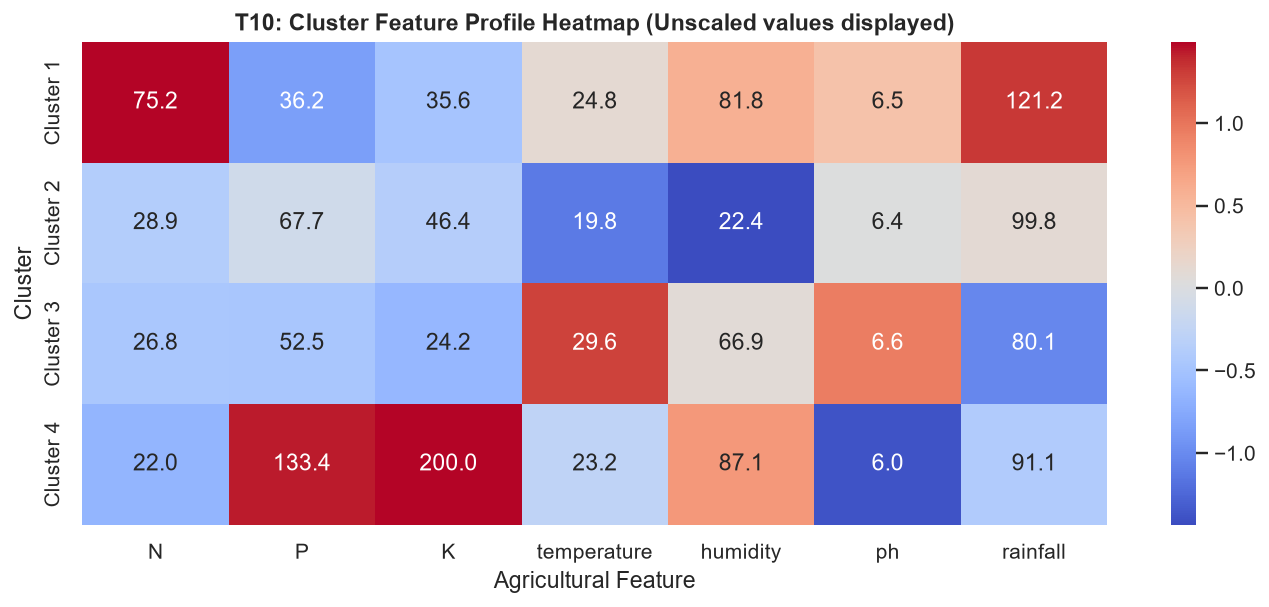

In [7]:
df_profile = df[features].copy()
df_profile['Cluster'] = [f'Cluster {c+1}' for c in agg_labels]
profile_means = df_profile.groupby('Cluster').mean().round(2)
print('=== Agro-Climatic Cluster Mean Profiles ===')
display(profile_means)

# Bar chart of normalized cluster means
profile_norm = (profile_means - profile_means.mean()) / profile_means.std()
plt.figure(figsize=(10, 4.5), dpi=140)
sns.heatmap(profile_norm, annot=profile_means.values, fmt='.1f', cmap='coolwarm', cbar=True)
plt.title('T10: Cluster Feature Profile Heatmap (Unscaled values displayed)', fontsize=12, fontweight='bold')
plt.ylabel('Cluster')
plt.xlabel('Agricultural Feature')
plt.tight_layout()
plt.show()

### 🎓 Viva Voce Questions & Answers (Tutorial 10)

1. **Q: What is the fundamental difference between Agglomerative and Divisive Hierarchical Clustering?**
   - **A:** Agglomerative is a **bottom-up** approach where each sample starts in its own cluster and pairs are iteratively merged. Divisive is a **top-down** approach where all samples start in a single master cluster and are recursively split.

2. **Q: How does Ward's Linkage work and why is it preferred here?**
   - **A:** Ward's linkage merges the pair of clusters that leads to the minimum increase in total within-cluster variance (Error Sum of Squares, ESS). It creates compact, spherical, balanced clusters similar to K-Means but without stochastic centroid initialization.

3. **Q: What is the computational complexity of Hierarchical Clustering?**
   - **A:** Time complexity is $\mathcal{O}(n^3)$ in basic implementations and $\mathcal{O}(n^2 \log n)$ using priority queues/heaps. Space complexity is $\mathcal{O}(n^2)$ to store the pairwise distance matrix.